# 07_Routing_Threshold — Coverage, Precision & Business Impact

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
lock = json.load(open('reports/phase5/ROUTING_LOCK.json', encoding='utf-8'))
sel = pd.read_csv('reports/phase5/val_selection.csv')
res = pd.read_csv('reports/phase5/routing_results.csv')
psr = pd.read_csv('reports/phase5/routing_per_service.csv')
imp = pd.read_csv('reports/phase5/business_impact.csv')
print(f"Locked rule: {lock['rule']} | threshold: {lock['threshold']} | target precision: {lock['target_precision']}")

Locked rule: calibrated_argmax | threshold: 0.79 | target precision: 0.95


## 1. Selection on Validation

In [4]:
print(sel.to_string(index=False))

             rule  target_precision  threshold  val_coverage  val_precision  val_macro_f1_no_threshold
calibrated_argmax              0.95      0.790        0.6405         0.9507                     0.8306
calibrated_argmax              0.90      0.585        0.8550         0.9003                     0.8306
calibrated_argmax              0.97      0.870        0.4948         0.9710                     0.8306
   raw_svc_argmax              0.95      0.790        0.6405         0.9507                     0.8318
   raw_svc_argmax              0.90      0.585        0.8550         0.9003                     0.8318
   raw_svc_argmax              0.97      0.870        0.4948         0.9710                     0.8318


## 2. Coverage vs Precision

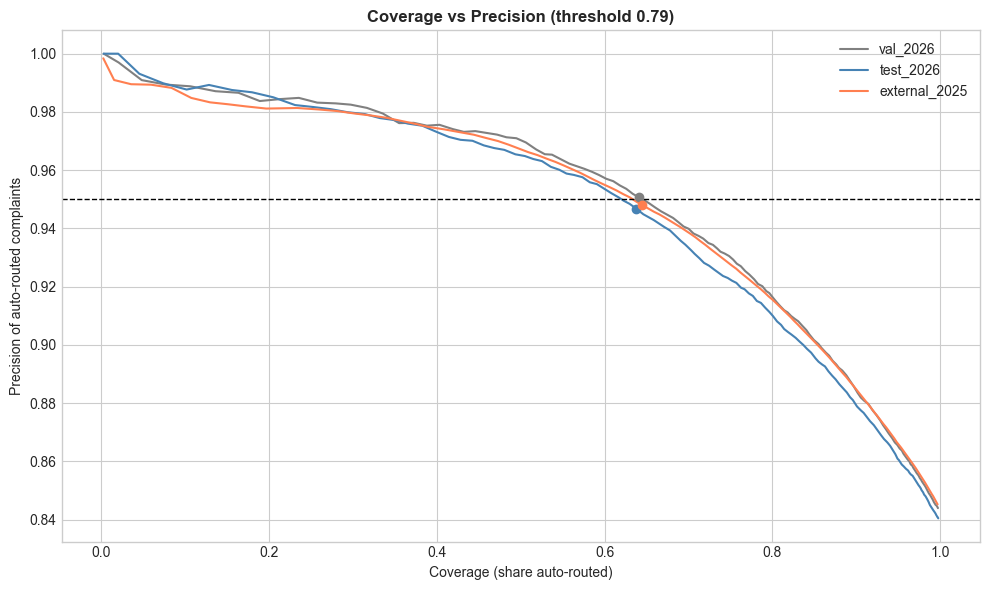

✓ Saved: 07_coverage_precision.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for ds, color in [('val_2026', 'grey'), ('test_2026', 'steelblue'), ('external_2025', 'coral')]:
    c = pd.read_csv(f"reports/phase5/curve_{ds}_{lock['rule']}.csv")
    ax.plot(c['coverage'], c['precision'], label=ds, color=color)
    p = c[c['threshold'] == lock['threshold']]
    ax.scatter(p['coverage'], p['precision'], color=color, zorder=3)
ax.axhline(lock['target_precision'], ls='--', color='black', lw=1)
ax.set_xlabel('Coverage (share auto-routed)'); ax.set_ylabel('Precision of auto-routed complaints')
ax.set_title(f"Coverage vs Precision (threshold {lock['threshold']})", fontsize=12, fontweight='bold'); ax.legend()
plt.tight_layout()
plt.savefig('output/07_coverage_precision.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 07_coverage_precision.png')

## 3. Results at the Locked Threshold

In [6]:
print(res.to_string(index=False))

      dataset      n  coverage     coverage_ci95  precision_auto    precision_ci95  macro_f1_no_threshold  accuracy_human_queue_if_model_kept
     val_2026  15945    0.6405 [0.6336 ; 0.6485]          0.9507 [0.9465 ; 0.9550]                 0.8306                              0.6494
    test_2026  15947    0.6377 [0.6301 ; 0.6449]          0.9468 [0.9427 ; 0.9513]                 0.8283                              0.6500
external_2025 251388    0.6449 [0.6431 ; 0.6467]          0.9480 [0.9469 ; 0.9491]                 0.8423                              0.6541


## 4. By Service (test 2026)

                            dataset  share_auto_routed_pct  precision_auto_pred_as_service  n_true
service                                                                                           
Comptes & Dépôts          test_2026                  51.44                          0.9094    3194
Crédit immobilier         test_2026                  71.27                          0.9728    1166
Crédits aux particuliers  test_2026                  62.38                          0.9437    2140
Monétique                 test_2026                  62.38                          0.9501    3251
Recouvrement              test_2026                  81.17                          0.9690    4732
Transferts & Paiements    test_2026                  33.61                          0.8436    1464


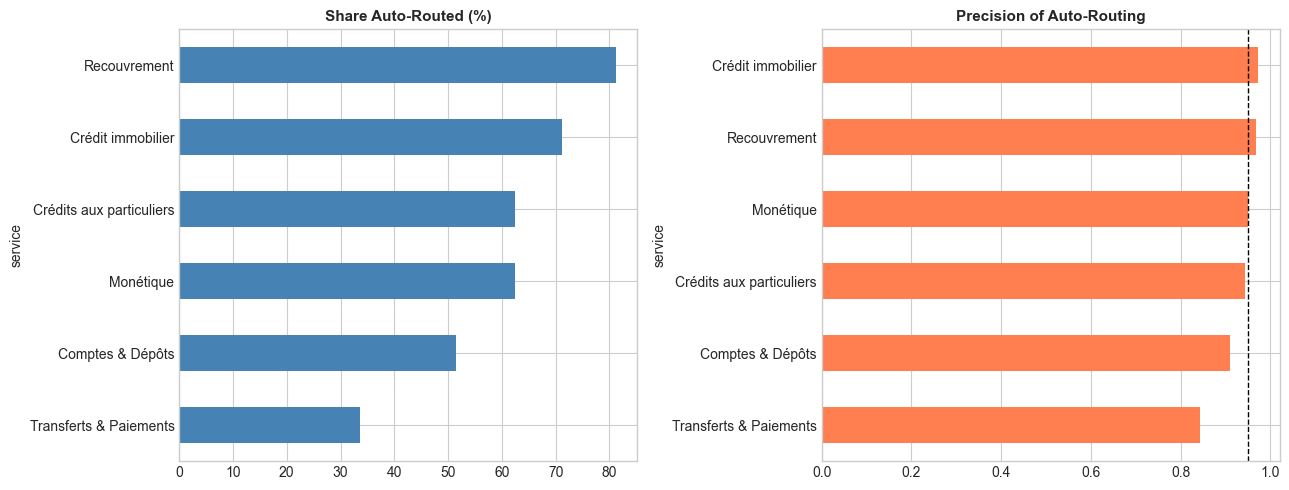

✓ Saved: 07_per_service_routing.png


In [7]:
t = psr[psr['dataset'] == 'test_2026'].set_index('service')
print(t.to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t['share_auto_routed_pct'].sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Share Auto-Routed (%)', fontsize=11, fontweight='bold')
t['precision_auto_pred_as_service'].sort_values().plot.barh(ax=axes[1], color='coral')
axes[1].axvline(lock['target_precision'], ls='--', color='black', lw=1)
axes[1].set_title('Precision of Auto-Routing', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('output/07_per_service_routing.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 07_per_service_routing.png')

## 5. Business Impact (illustrative volume, assumed triage time)

      dataset  triage_minutes_assumed  auto_routed_per_month  human_review_per_month  misrouted_auto_per_month  triage_hours_saved_per_month
    test_2026                       1                    638                     362                        34                          10.6
    test_2026                       2                    638                     362                        34                          21.3
    test_2026                       3                    638                     362                        34                          31.9
    test_2026                       5                    638                     362                        34                          53.1
external_2025                       1                    645                     355                        34                          10.7
external_2025                       2                    645                     355                        34                          21.5
external_2025

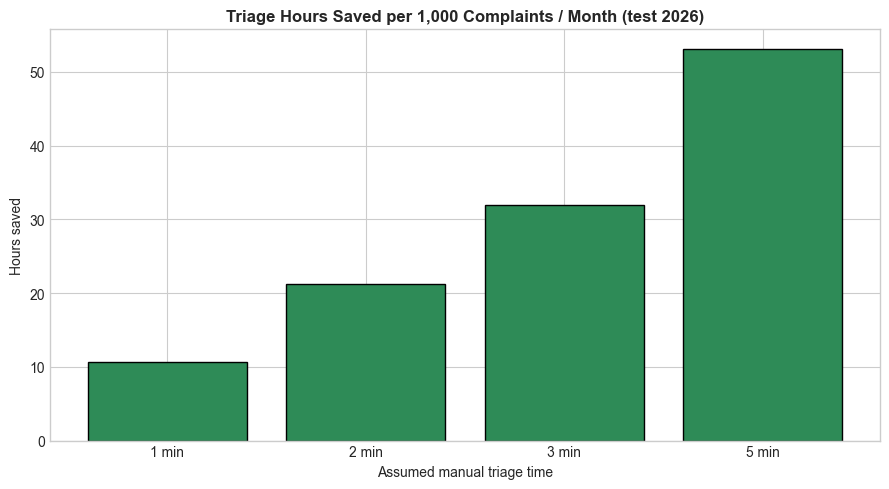

✓ Saved: 07_business_impact.png


In [8]:
print(imp.to_string(index=False))
d = imp[imp['dataset'] == 'test_2026']
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(d['triage_minutes_assumed'].astype(str) + ' min', d['triage_hours_saved_per_month'], color='seagreen',
       edgecolor='black')
ax.set_title('Triage Hours Saved per 1,000 Complaints / Month (test 2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Assumed manual triage time'); ax.set_ylabel('Hours saved')
plt.tight_layout()
plt.savefig('output/07_business_impact.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 07_business_impact.png')